In [1]:
%pip install numpy matplotlib
%pip install tensorflow
%pip install ipython pydot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 27.3 MB/s  0:00:00


In [2]:
!apt-get -qq install graphviz

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("TensorFlow executing eagerly:", tf.executing_eagerly())
print("Core image-classification libraries imported successfully.")

TensorFlow: 2.21.0
TensorFlow executing eagerly: True
Core image-classification libraries imported successfully.


In [4]:
import shutil
import pydot
from IPython.display import Image, display

dot_path = shutil.which("dot")
print("pydot:", pydot.__version__)
print("Graphviz executable:", dot_path)
if dot_path is None:
    print("Install Graphviz before running keras.utils.plot_model().")

pydot: 4.0.1
Graphviz executable: /usr/bin/dot


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Keras backend: TensorFlow (via tf.keras)")

TensorFlow: 2.21.0
Keras backend: TensorFlow (via tf.keras)


In [6]:
(x_train_full, y_train_full), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

print("Original training images:", x_train_full.shape)
print("Original training labels:", y_train_full.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test.shape)
print("First 10 training labels:", y_train_full[:10])
print("Pixel data type:", x_train_full.dtype)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Original training images: (60000, 28, 28)
Original training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
First 10 training labels: [5 0 4 1 9 2 1 3 1 4]
Pixel data type: uint8


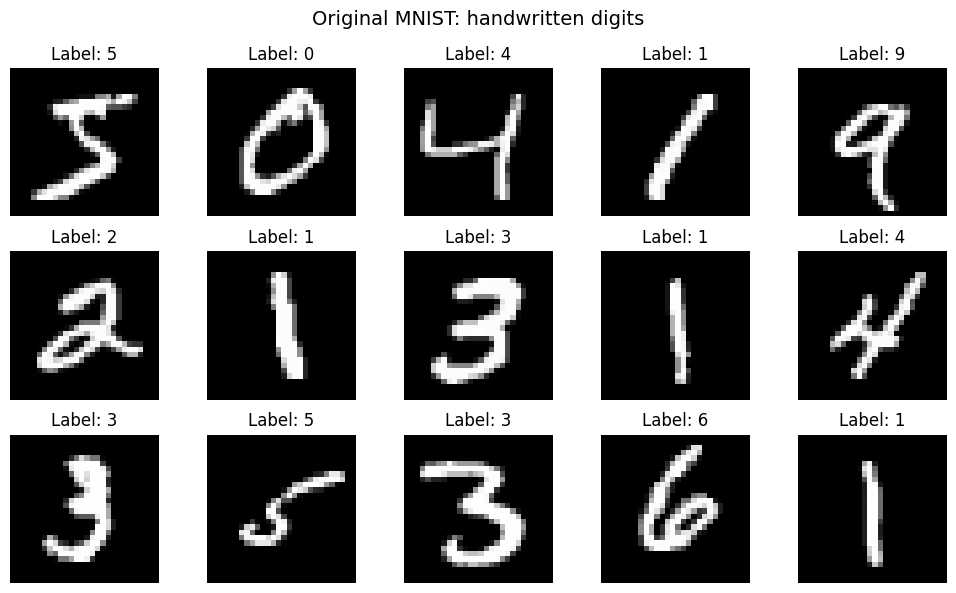

In [10]:
# Question 1 b
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label: {y_train_full[i]}")
    ax.axis("off")
fig.suptitle("Original MNIST: handwritten digits", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
print("One image shape:", x_train_full[0].shape)
print("One image minimum:", x_train_full[0].min())
print("One image maximum:", x_train_full[0].max())

# Reserve the last 12,000 original training images for validation.
# The test set is not used during model selection or training.
x_train = x_train_full[:48000].astype("float32") / 255.0
y_train = y_train_full[:48000]
x_val = x_train_full[48000:].astype("float32") / 255.0
y_val = y_train_full[48000:]
x_test = x_test_raw.astype("float32") / 255.0

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Normalized value range:", x_train.min(), x_train.max())

One image shape: (28, 28)
One image minimum: 0
One image maximum: 255
Training: (48000, 28, 28) (48000,)
Validation: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)
Normalized value range: 0.0 1.0


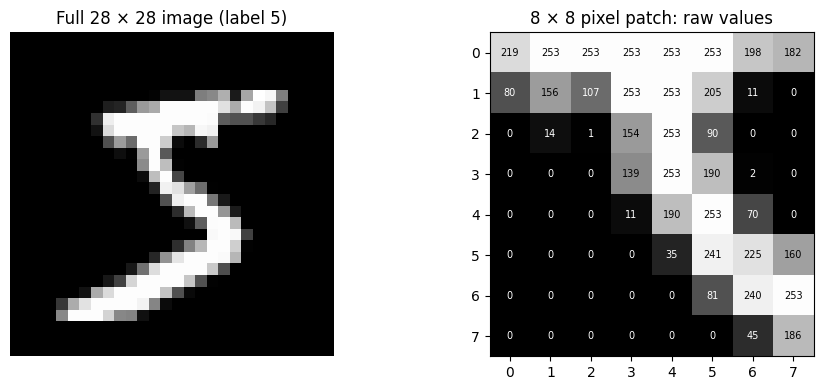

In [9]:
import matplotlib.pyplot as plt

image = x_train_full[0]
patch = image[8:16, 8:16]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Full 28 × 28 image (label {y_train_full[0]})")
axes[0].axis("off")

axes[1].imshow(patch, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("8 × 8 pixel patch: raw values")
axes[1].set_xticks(range(patch.shape[1]))
axes[1].set_yticks(range(patch.shape[0]))
for r in range(patch.shape[0]):
    for c in range(patch.shape[1]):
        value = int(patch[r, c])
        axes[1].text(c, r, str(value), ha="center", va="center",
                     fontsize=7, color="black" if value > 130 else "white")
plt.tight_layout()
plt.show()

In [11]:
def build_model():
    inputs = keras.Input(shape=(28, 28), name="Image")
    h = layers.Flatten(name="Flatten")(inputs)
    h = layers.Dense(256, activation="relu", name="Hidden_1")(h)
    h = layers.Dense(256, activation="relu", name="Hidden_2")(h)
    outputs = layers.Dense(10, activation="softmax", name="Digit_probabilities")(h)
    return keras.Model(inputs=inputs, outputs=outputs, name="MNIST_DNN")

keras.utils.set_random_seed(42)
model = build_model()
model.summary()

Model: "MNIST_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Image (InputLayer)              │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Digit_probabilities (Dense)     │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

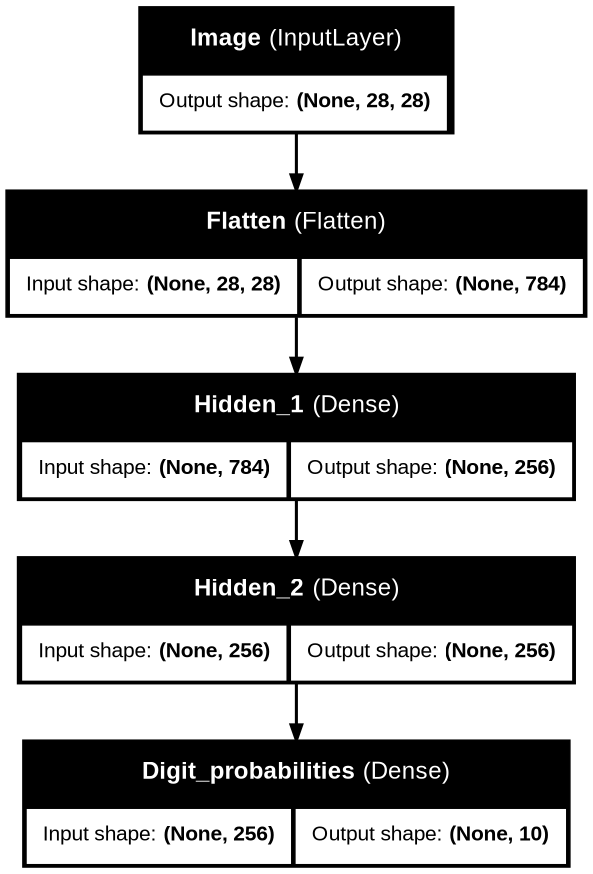

In [15]:
from IPython.display import Image, display

# Requires pydot and Graphviz as noted in the setup section.
keras.utils.plot_model(
    model,
    to_file="mnist_dnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=110,
)
display(Image(filename="mnist_dnn_architecture.png"))

In [16]:
probabilities = np.array([0.04, 0.03, 0.05, 0.70, 0.04,
                          0.03, 0.03, 0.02, 0.03, 0.03], dtype="float64")
label_sparse = 3
label_one_hot = np.eye(10)[label_sparse]

loss_sparse = -np.log(probabilities[label_sparse])
loss_one_hot = -np.sum(label_one_hot * np.log(probabilities))
print("Sparse loss:", round(float(loss_sparse), 6))
print("One-hot loss:", round(float(loss_one_hot), 6))
print("Same result:", np.isclose(loss_sparse, loss_one_hot))

Sparse loss: 0.356675
One-hot loss: 0.356675
Same result: True


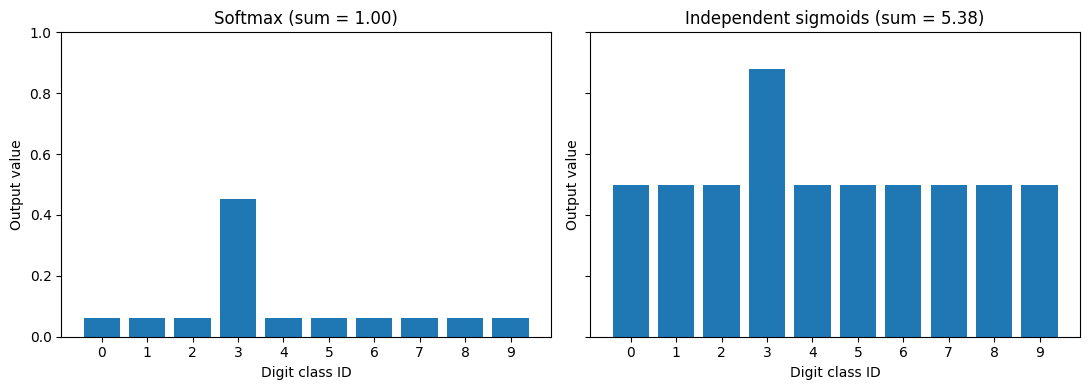

In [17]:
import numpy as np
import matplotlib.pyplot as plt

logits = np.array([0., 0., 0., 2., 0., 0., 0., 0., 0., 0.])
shifted = logits - np.max(logits)
exp_scores = np.exp(shifted)
softmax = exp_scores / exp_scores.sum()
sigmoids = 1.0 / (1.0 + np.exp(-logits))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].bar(range(10), softmax)
axes[0].set_title(f"Softmax (sum = {softmax.sum():.2f})")
axes[1].bar(range(10), sigmoids)
axes[1].set_title(f"Independent sigmoids (sum = {sigmoids.sum():.2f})")
for ax in axes:
    ax.set_xticks(range(10))
    ax.set_xlabel("Digit class ID")
    ax.set_ylabel("Output value")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [18]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

batch_size = 64
max_epochs = 25

In [20]:
baseline_history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=batch_size,
    epochs=max_epochs,
    verbose=2,
)

print("Completed epochs:", len(baseline_history.history["loss"]))
print("Final training loss:", baseline_history.history["loss"][-1])
print("Final validation loss:", baseline_history.history["val_loss"][-1])

Epoch 1/25
750/750 - 8s - 10ms/step - accuracy: 0.9267 - loss: 0.2513 - val_accuracy: 0.9572 - val_loss: 0.1388
Epoch 2/25
750/750 - 9s - 12ms/step - accuracy: 0.9709 - loss: 0.0957 - val_accuracy: 0.9668 - val_loss: 0.1105
Epoch 3/25
750/750 - 7s - 9ms/step - accuracy: 0.9818 - loss: 0.0591 - val_accuracy: 0.9730 - val_loss: 0.0945
Epoch 4/25
750/750 - 5s - 7ms/step - accuracy: 0.9876 - loss: 0.0408 - val_accuracy: 0.9709 - val_loss: 0.1049
Epoch 5/25
750/750 - 7s - 9ms/step - accuracy: 0.9901 - loss: 0.0314 - val_accuracy: 0.9714 - val_loss: 0.1077
Epoch 6/25
750/750 - 6s - 8ms/step - accuracy: 0.9916 - loss: 0.0256 - val_accuracy: 0.9753 - val_loss: 0.0971
Epoch 7/25
750/750 - 6s - 9ms/step - accuracy: 0.9930 - loss: 0.0217 - val_accuracy: 0.9714 - val_loss: 0.1230
Epoch 8/25
750/750 - 6s - 8ms/step - accuracy: 0.9937 - loss: 0.0184 - val_accuracy: 0.9737 - val_loss: 0.1159
Epoch 9/25
750/750 - 6s - 7ms/step - accuracy: 0.9938 - loss: 0.0186 - val_accuracy: 0.9758 - val_loss: 0.1186

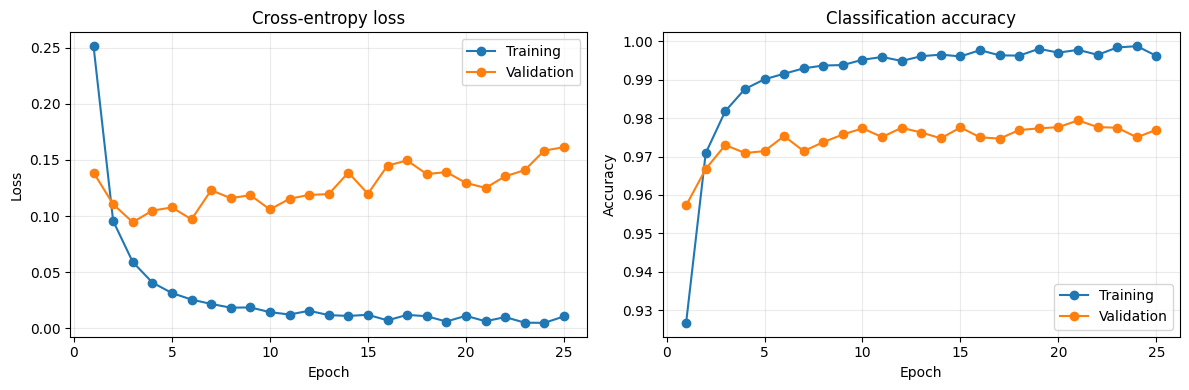

In [21]:
import numpy as np
import matplotlib.pyplot as plt

hist = baseline_history.history
epoch_numbers = np.arange(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epoch_numbers, hist["loss"], marker="o", label="Training")
axes[0].plot(epoch_numbers, hist["val_loss"], marker="o", label="Validation")
axes[0].set_title("Cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epoch_numbers, hist["accuracy"], marker="o", label="Training")
axes[1].plot(epoch_numbers, hist["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Classification accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [22]:
keras.utils.set_random_seed(42)
early_model = build_model()
early_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

early_history = early_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=batch_size,
    epochs=max_epochs,
    callbacks=[early_stop],
    verbose=2,
)

best_epoch = int(np.argmin(early_history.history["val_loss"])) + 1
last_epoch = len(early_history.history["loss"])
print("Best recorded validation-loss epoch:", best_epoch)
print("Last completed training epoch:", last_epoch)
print("Best recorded validation loss:", min(early_history.history["val_loss"]))

Epoch 1/25
750/750 - 8s - 10ms/step - accuracy: 0.9267 - loss: 0.2513 - val_accuracy: 0.9572 - val_loss: 0.1388
Epoch 2/25
750/750 - 5s - 7ms/step - accuracy: 0.9709 - loss: 0.0957 - val_accuracy: 0.9668 - val_loss: 0.1105
Epoch 3/25
750/750 - 7s - 9ms/step - accuracy: 0.9818 - loss: 0.0591 - val_accuracy: 0.9730 - val_loss: 0.0945
Epoch 4/25
750/750 - 5s - 7ms/step - accuracy: 0.9876 - loss: 0.0408 - val_accuracy: 0.9709 - val_loss: 0.1049
Epoch 5/25
750/750 - 6s - 8ms/step - accuracy: 0.9901 - loss: 0.0314 - val_accuracy: 0.9714 - val_loss: 0.1077
Epoch 6/25
750/750 - 9s - 13ms/step - accuracy: 0.9916 - loss: 0.0256 - val_accuracy: 0.9753 - val_loss: 0.0971
Best recorded validation-loss epoch: 3
Last completed training epoch: 6
Best recorded validation loss: 0.09449432045221329


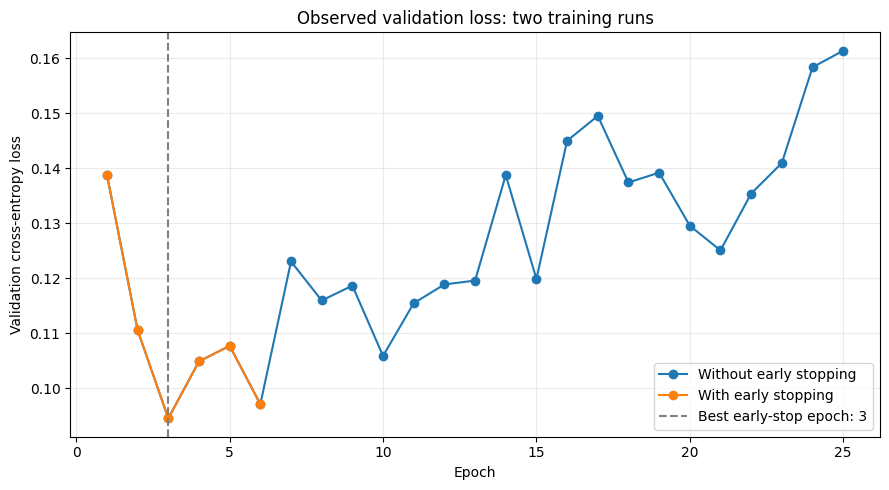

In [23]:
import numpy as np
import matplotlib.pyplot as plt

baseline_epochs = np.arange(1, len(baseline_history.history["val_loss"]) + 1)
early_epochs = np.arange(1, len(early_history.history["val_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(baseline_epochs, baseline_history.history["val_loss"],
         marker="o", label="Without early stopping")
plt.plot(early_epochs, early_history.history["val_loss"],
         marker="o", label="With early stopping")
plt.axvline(best_epoch, linestyle="--", color="gray",
            label=f"Best early-stop epoch: {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("Observed validation loss: two training runs")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [24]:
test_loss, test_accuracy = early_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

sample_index = 0
sample_probs = early_model.predict(x_test[sample_index:sample_index + 1], verbose=0)[0]
sample_prediction = int(np.argmax(sample_probs))
print("Sample true digit:", int(y_test[sample_index]))
print("Sample predicted digit:", sample_prediction)
print("Sum of sample probabilities:", sample_probs.sum())

Test loss: 0.0914
Test accuracy: 97.3600%
Sample true digit: 7
Sample predicted digit: 7
Sum of sample probabilities: 1.0000001


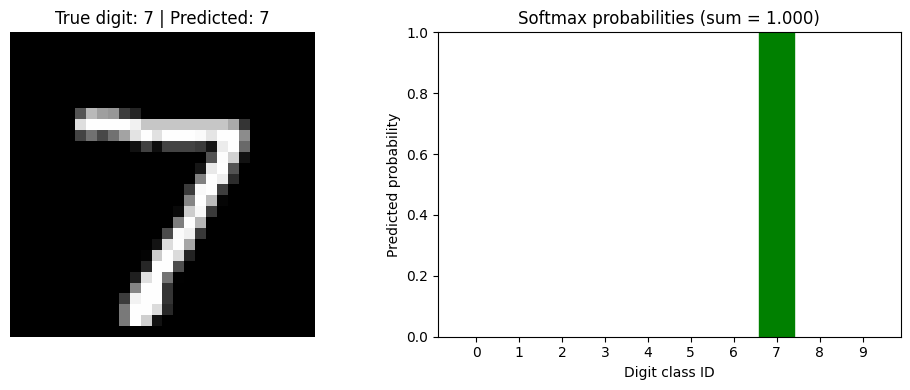

In [25]:
import numpy as np
import matplotlib.pyplot as plt

sample_index = 0
probs = early_model.predict(x_test[sample_index:sample_index + 1], verbose=0)[0]
predicted = int(np.argmax(probs))
true_digit = int(y_test[sample_index])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(x_test[sample_index], cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"True digit: {true_digit} | Predicted: {predicted}")
axes[0].axis("off")

bars = axes[1].bar(range(10), probs)
bars[predicted].set_color("green" if predicted == true_digit else "red")
axes[1].set_xticks(range(10))
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Digit class ID")
axes[1].set_ylabel("Predicted probability")
axes[1].set_title(f"Softmax probabilities (sum = {probs.sum():.3f})")
plt.tight_layout()
plt.show()

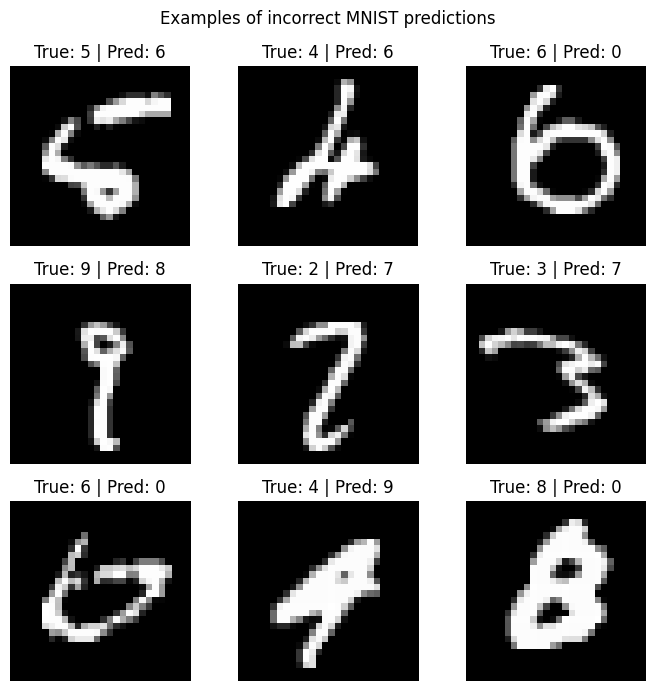

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Inspect a fixed subset; use more images if very few errors occur.
subset_size = 1000
predicted_probs = early_model.predict(x_test[:subset_size], verbose=0)
predicted_digits = np.argmax(predicted_probs, axis=1)
wrong_indices = np.flatnonzero(predicted_digits != y_test[:subset_size])[:9]

if len(wrong_indices) == 0:
    print("No mistakes found in the first", subset_size, "test images.")
else:
    fig, axes = plt.subplots(3, 3, figsize=(7, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, wrong_indices):
        ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"True: {y_test[idx]} | Pred: {predicted_digits[idx]}")
    fig.suptitle("Examples of incorrect MNIST predictions")
    plt.tight_layout()
    plt.show()